In [ ]:
#NOTES:
# - QCEC runs sequatially right now, so its ZX checker does not run -> create a separate benchmark for that
# - QCEC also looks like it has a race condition when run in parallel (once ZX finished early with EQ other time DD with NEQ)
#
# - Quokka has a lot of configurable argumets -> also do pauli benchmark
#    (Are there different backends ?)
# - Quokka also looks like has a issue when the global phase is -1
#
# - AutoQ has no additional modes
#
# - Feynman has no additional modes
#
# - SliQEC has no additional modes (It supports STRONG PARTIAL EQUIVALENCE which we are also interested in)

In [1]:
import os, sys
os.chdir(os.path.expanduser("~/Personal/VUT-FIT/BcWork/quantum-eval/eval"))   # folder with eval_functions.py
sys.path.insert(0, os.getcwd())

import importlib, eval_functions
importlib.reload(eval_functions)          # picks up changes to eval_functions.py without restarting
from eval_functions import *

RES = "../results"                           # where results/<tool>/*.tasks are (repo folder)

import warnings
warnings.filterwarnings("ignore", message="divide by zero encountered in log10")

In [2]:
# 2. load -> creates df
df = load_tasks(f"{RES}/*/*.tasks", drop_first=True)
df.shape

loaded: eq_approx-opt/autoq <- ../results/autoq/eq_approx-opt-to300-autoq-2026-11-08-08-28.tasks, eq_approx-opt/feynman <- ../results/feynman/eq_approx-opt-to300-feynman-2026-11-08-22-02.tasks, eq_approx-opt/qcec <- ../results/qcec/eq_approx-opt-to300-qcec-2026-11-07-11-10.tasks, eq_approx-opt/quokka <- ../results/quokka/eq_approx-opt-to300-quokka-2026-11-09-20-01.tasks, eq_approx-opt/sliqec <- ../results/sliqec/eq_approx-opt-to300-sliqec-2026-11-07-14-03.tasks, eq_approx-shift4/autoq <- ../results/autoq/eq_approx-shift4-to300-autoq-2026-11-08-08-28.tasks, eq_approx-shift4/feynman <- ../results/feynman/eq_approx-shift4-to300-feynman-2026-11-08-22-02.tasks, eq_approx-shift4/qcec <- ../results/qcec/eq_approx-shift4-to300-qcec-2026-11-07-11-10.tasks, eq_approx-shift4/quokka <- ../results/quokka/eq_approx-shift4-to300-quokka-2026-11-09-20-01.tasks, eq_approx-shift4/sliqec <- ../results/sliqec/eq_approx-shift4-to300-sliqec-2026-11-07-14-03.tasks, eq_approx-shift7/autoq <- ../results/autoq/e

(1497, 22)

loaded: eq_exact-opt/qcec <- ../results/qcec/eq_exact-opt-to300-qcec-2026-11-07-11-10.tasks, eq_exact-opt/sliqec <- ../results/sliqec/eq_exact-opt-to300-sliqec-2026-11-07-14-03.tasks


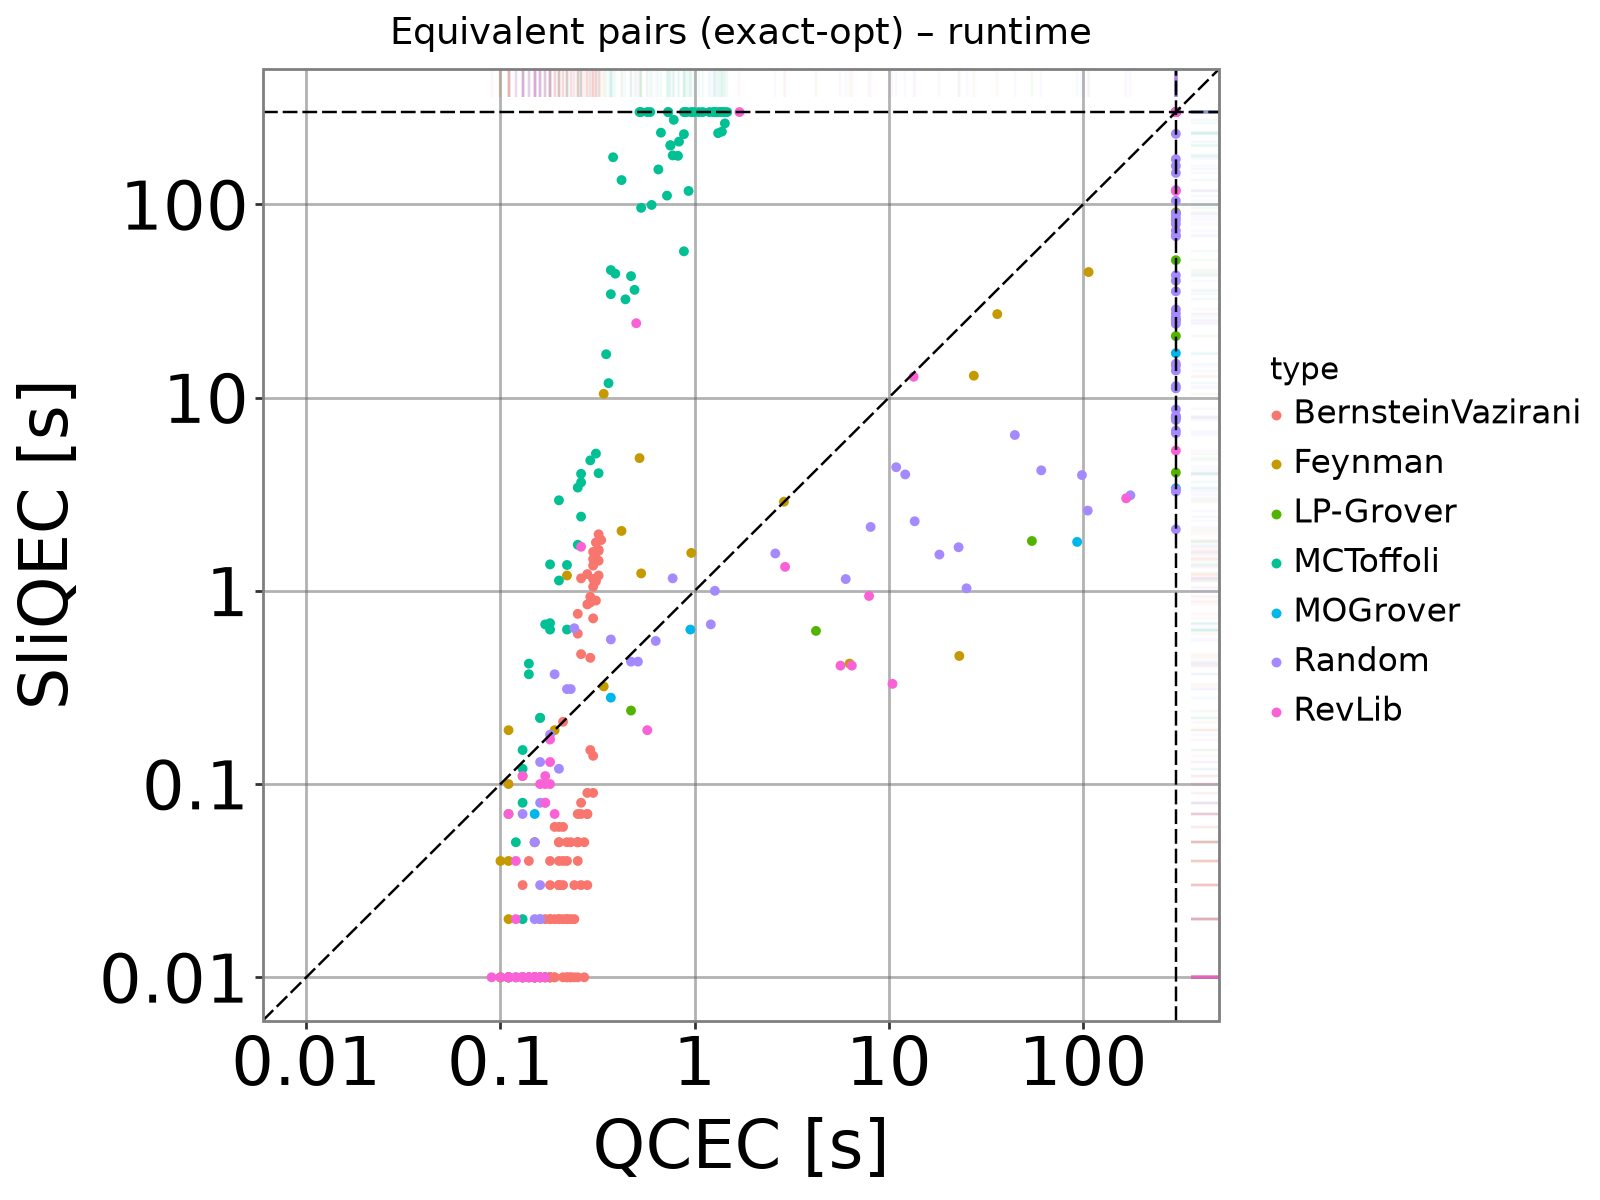

In [3]:
p = scatter_two_files(f"{RES}/qcec/eq_exact-opt-to300-qcec-2026-11-07-11-10.tasks",
                      f"{RES}/sliqec/eq_exact-opt-to300-sliqec-2026-11-07-14-03.tasks",
                      property="runtime", timeout=300,
                      title="Equivalent pairs (exact-opt) – runtime",
                      xname="QCEC [s]", yname="SliQEC [s]")
p

loaded: eq_exact-rm1/qcec <- ../results/qcec/eq_exact-rm1-to300-qcec-2026-11-07-11-10.tasks, eq_exact-rm1/sliqec <- ../results/sliqec/eq_exact-rm1-to300-sliqec-2026-11-07-14-03.tasks


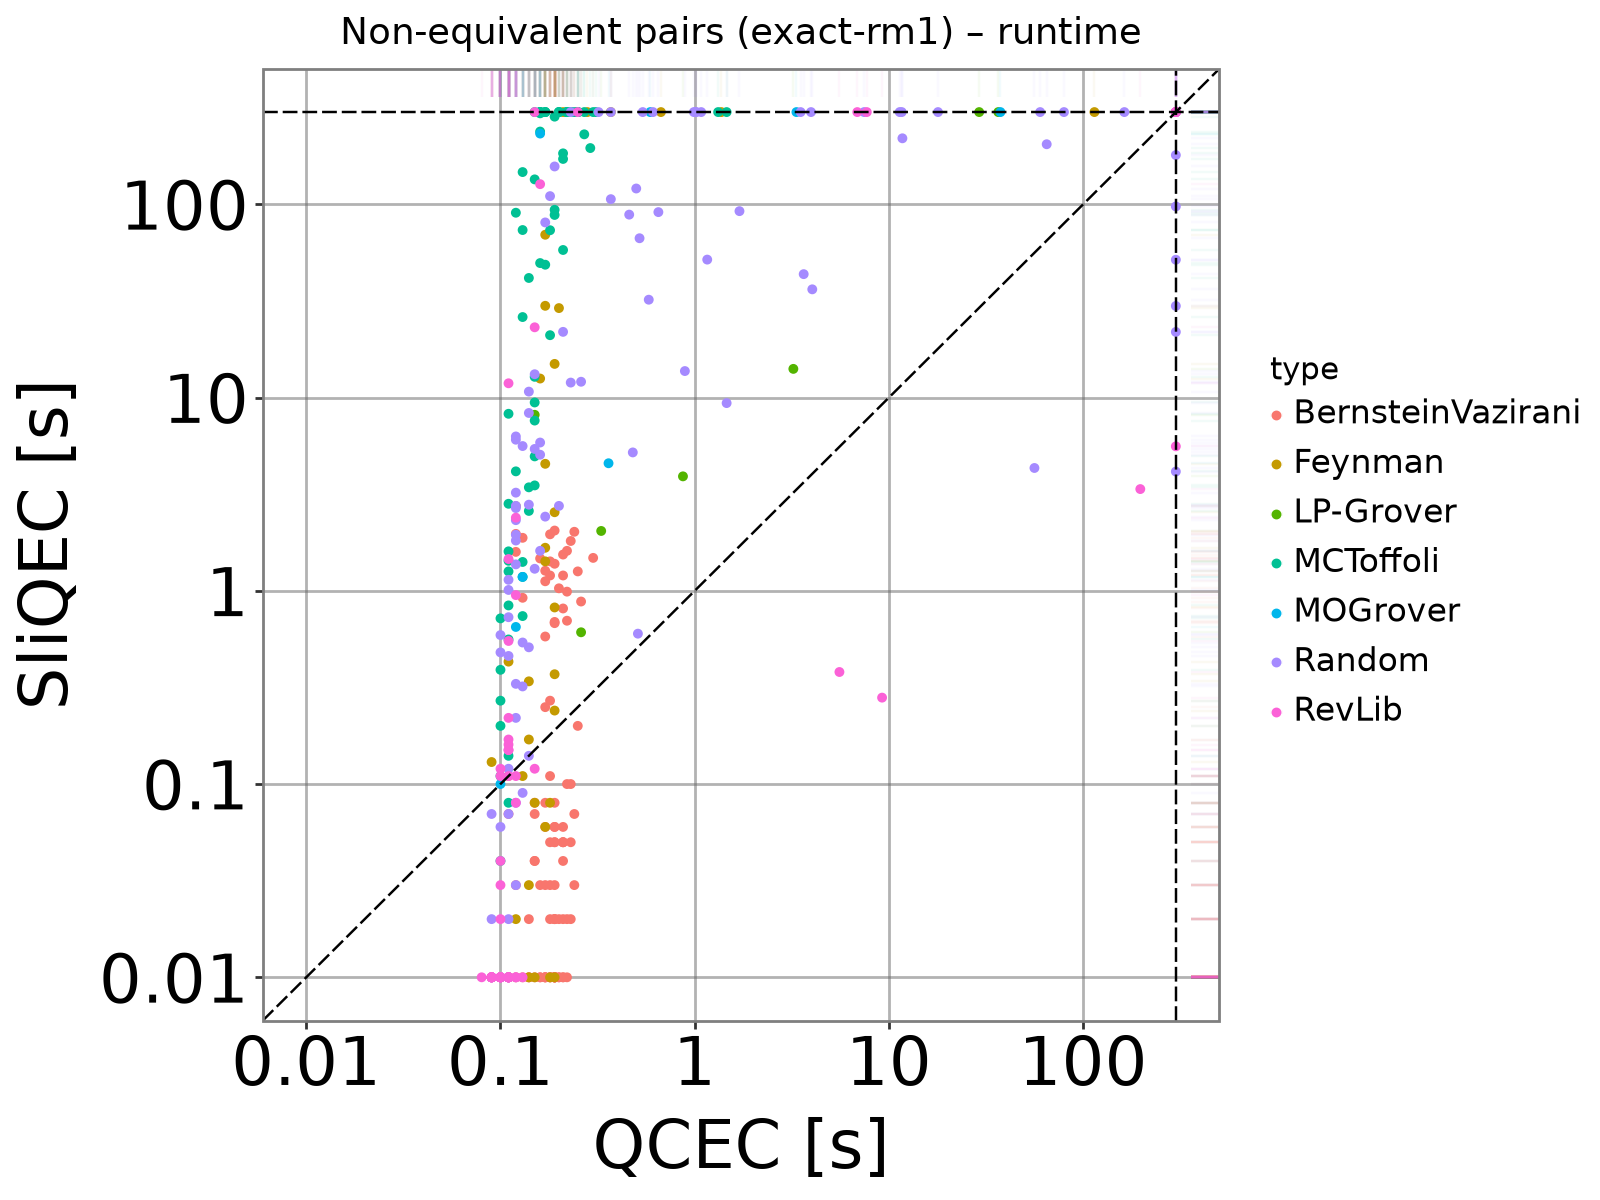

In [4]:
p = scatter_two_files(f"{RES}/qcec/eq_exact-rm1-to300-qcec-2026-11-07-11-10.tasks",
                      f"{RES}/sliqec/eq_exact-rm1-to300-sliqec-2026-11-07-14-03.tasks",
                      property="runtime", timeout=300,
                      title="Non-equivalent pairs (exact-rm1) – runtime",
                      xname="QCEC [s]", yname="SliQEC [s]")
p

loaded: eq_exact-rm3/qcec <- ../results/qcec/eq_exact-rm3-to300-qcec-2026-11-07-11-10.tasks, eq_exact-rm3/sliqec <- ../results/sliqec/eq_exact-rm3-to300-sliqec-2026-11-07-14-03.tasks


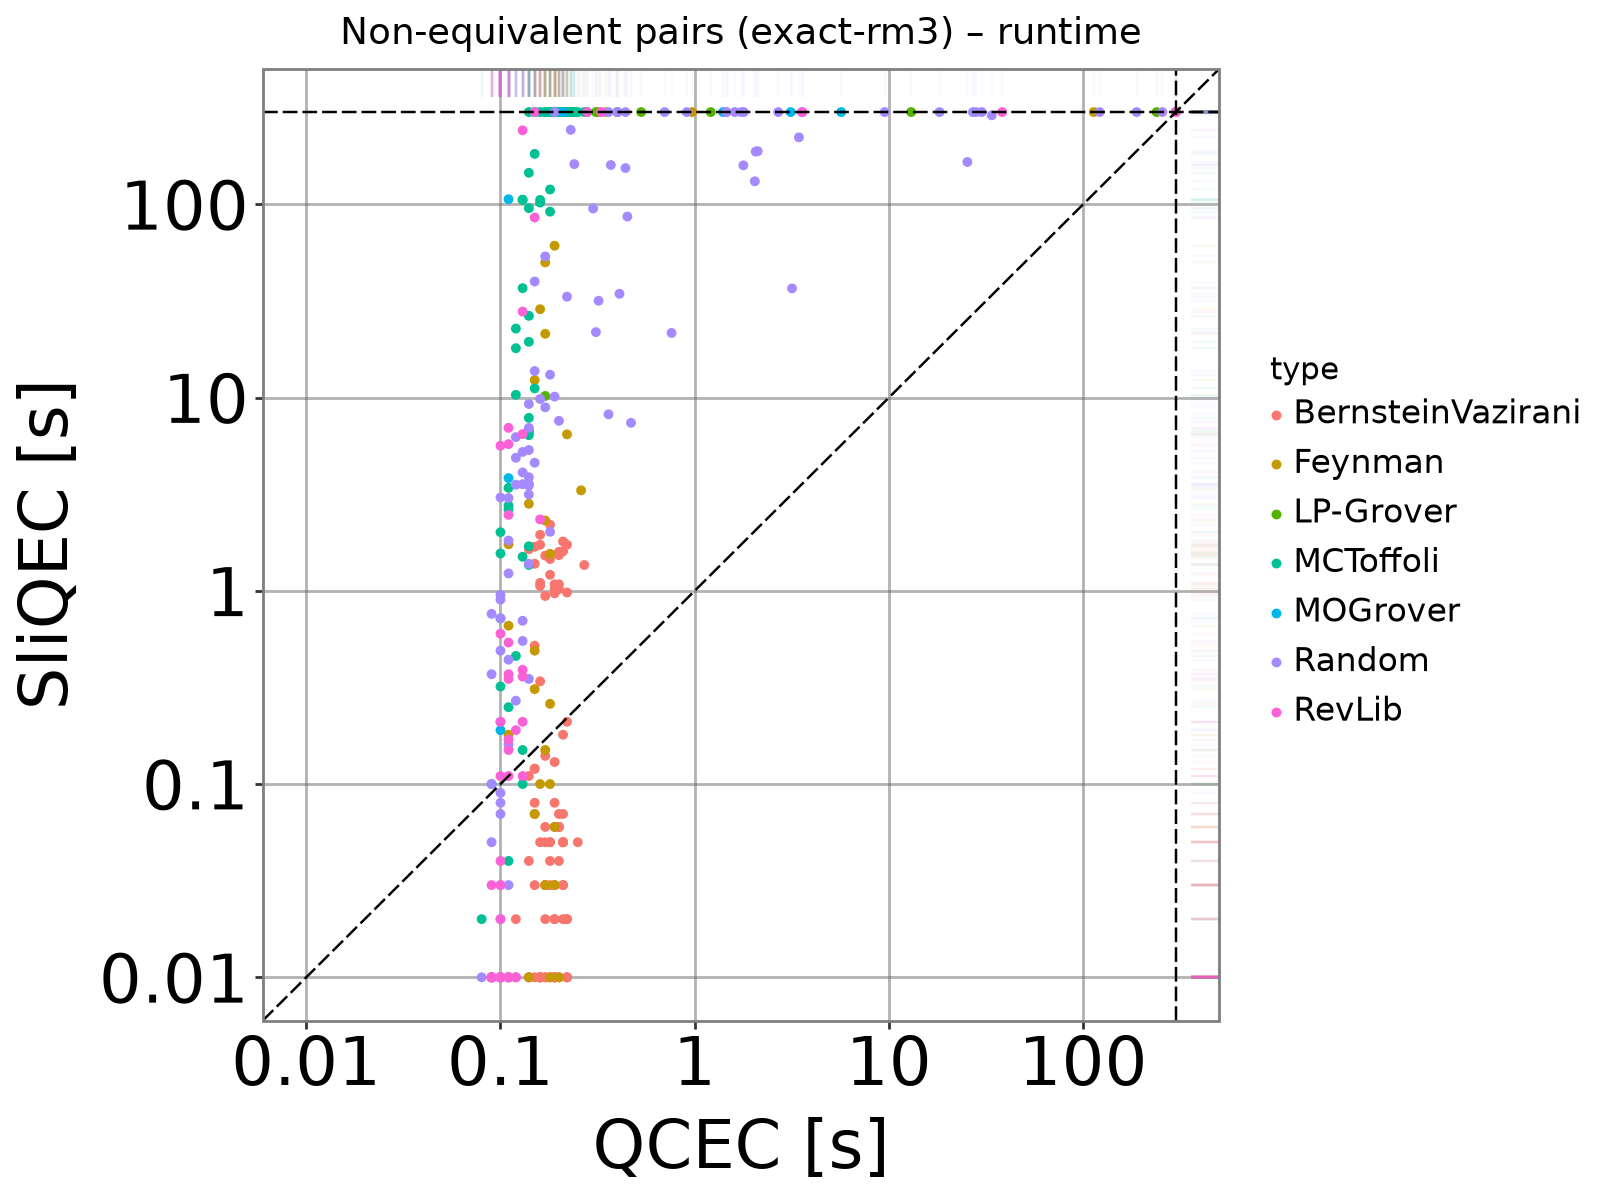

In [5]:
p = scatter_two_files(f"{RES}/qcec/eq_exact-rm3-to300-qcec-2026-11-07-11-10.tasks",
                      f"{RES}/sliqec/eq_exact-rm3-to300-sliqec-2026-11-07-14-03.tasks",
                      property="runtime", timeout=300,
                      title="Non-equivalent pairs (exact-rm3) – runtime",
                      xname="QCEC [s]", yname="SliQEC [s]")
p

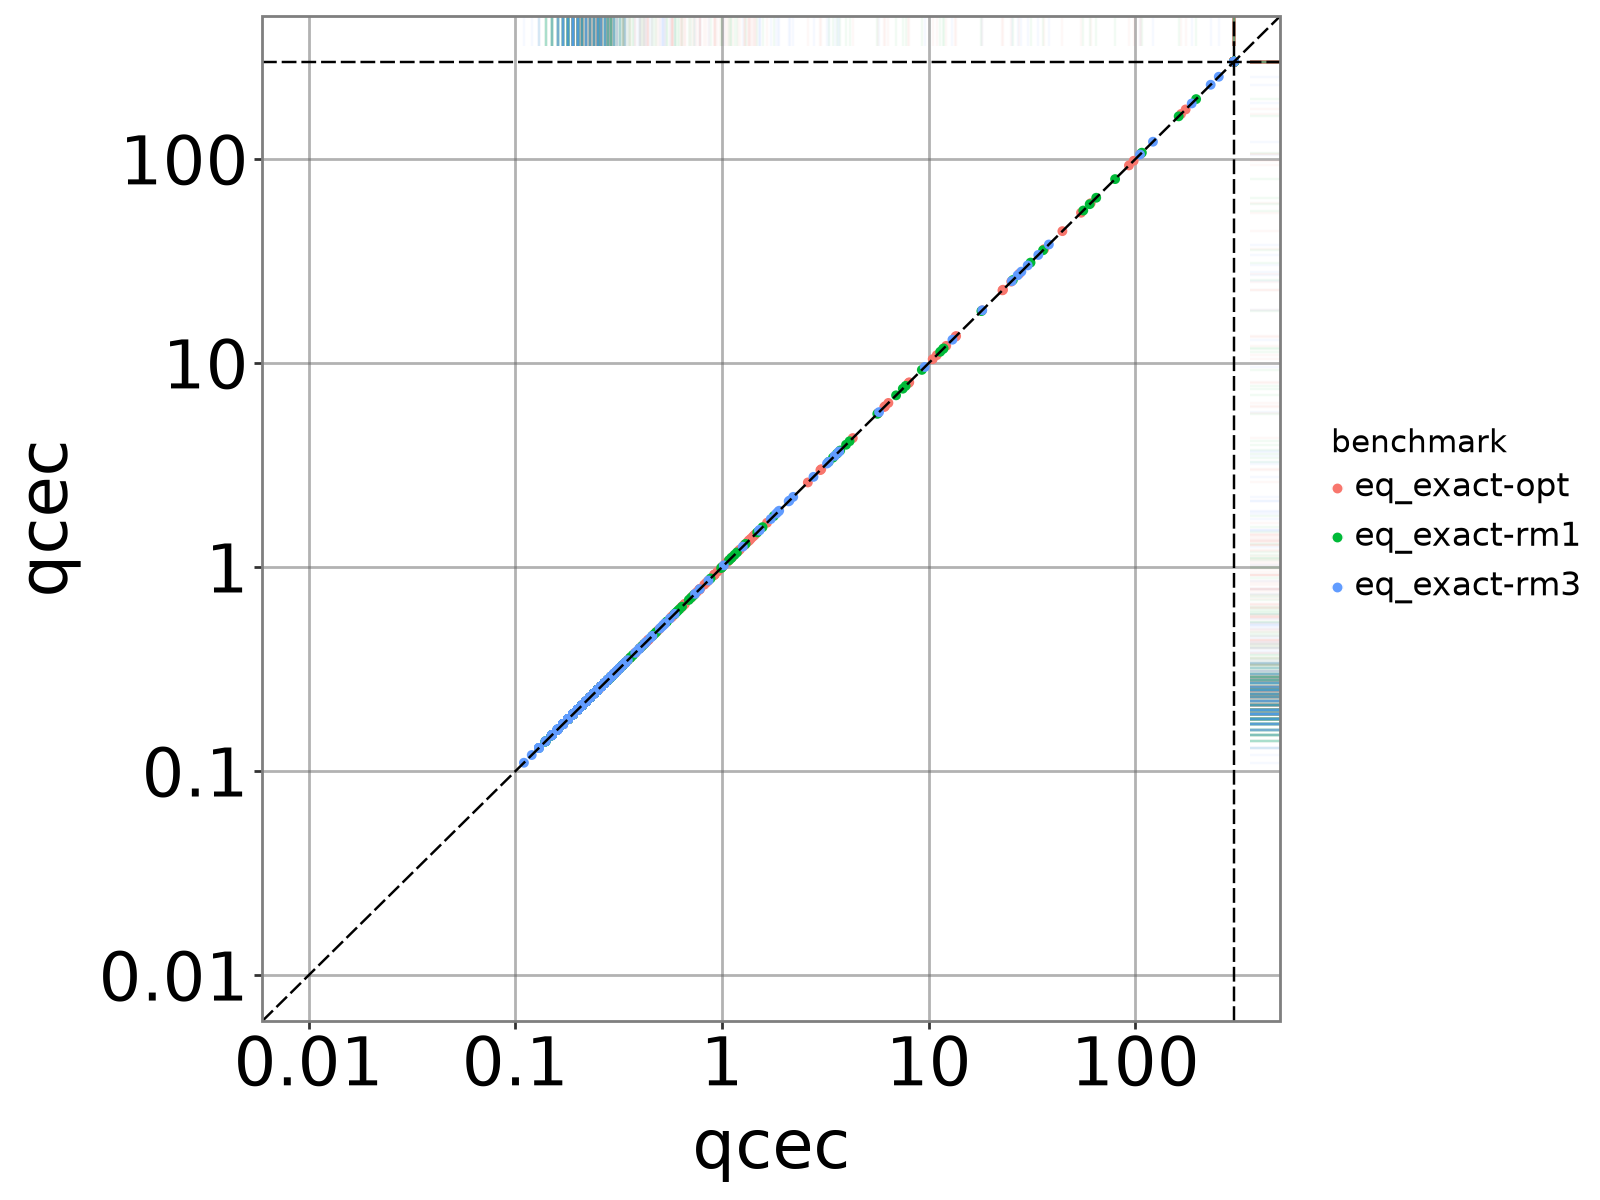

In [6]:
d = df[df.benchmark.str.startswith("eq_exact")].copy()
for t in ["qcec", "qcec"]:
    d.loc[~d[f"{t}-result"].isin(["eq", "neq"]), f"{t}-runtime"] = float("inf")
scatter_plot(d, "qcec", "qcec", timeout=300, clamp_domain=[0.01, 300],
             color_column="benchmark")

In [9]:
# Comparison PDFs: one PDF per tool, one scatter plot per other tool.
# First row: all benchmark sets together, colored by benchmark set (like the first scatter plot above).
# Then one row per benchmark set, colored by circuit type.
# The PDF's tool is always on the x-axis. Written to OUT_DIR as <tool>.pdf.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

TOOLS   = ["qcec", "sliqec", "feynman", "autoq"]   # tools compared in the plots
BENCHES = ["eq_exact-opt", "eq_exact-rm1", "eq_exact-rm3"]      # rows (approx sets left out)
PDF_TOOLS = ["qcec", "sliqec", "feynman", "autoq"]              # tools that get their own PDF (no quokka for now)
TIMEOUT = 300            # -s of the runs [s], upper edge of the plots
LOWEST  = 0.01           # lower edge of the plots [s]
OUT_DIR = "comparison-pdfs"
TOTAL_LABEL = "exact (all sets)"   # first row / last table: all sets in BENCHES together


def prepare_comparison(df):
    """Adds per tool: <tool>-time (plotted value) and <tool>-status (ok / wrong / unsolved).

    Time is the tool's wall time measured by the wrapper (###runtime).
    Runs without a correct answer (timeout, error, unknown, wrong answer) get TIMEOUT.
    The expected answer is eq for *-opt sets and neq for all others.
    """
    d = df.copy()
    d["type"] = d["name"].str.split("/").str[-2]
    expected = d["benchmark"].str.endswith("-opt").map({True: "eq", False: "neq"})
    for t in TOOLS:
        result = d[f"{t}-result"] if f"{t}-result" in d else pd.Series("ERR", index=d.index)
        time = pd.to_numeric(d[f"{t}-runtime.1"], errors="coerce") if f"{t}-runtime.1" in d else pd.Series(np.nan, index=d.index)
        answered = result.isin(["eq", "neq"])
        ok = answered & (result == expected) & time.notna()
        d[f"{t}-status"] = np.where(ok, "ok", np.where(answered, "wrong", "unsolved"))
        d[f"{t}-time"] = time.where(ok, TIMEOUT).clip(LOWEST, TIMEOUT)
    return d


def benchmark_rows(d):
    """(label, data, column to color by): all sets together first, then every benchmark set."""
    total = d[d["benchmark"].isin(BENCHES)].copy()
    total["set"] = total["benchmark"].str.removeprefix("eq_")
    rows = [(bench.removeprefix("eq_"), d[d["benchmark"] == bench], "type") for bench in BENCHES]
    return [(TOTAL_LABEL, total, "set")] + rows


def comparison_pdf(d, tool, file_name):
    """One page: rows = benchmark sets + their total, columns = the other tools, `tool` on the x-axis."""
    others = [t for t in TOOLS if t != tool]
    rows = benchmark_rows(d)

    fig, axes = plt.subplots(len(rows), len(others), squeeze=False,
                             figsize=(4.2 * len(others) + 2.2, 4.2 * len(rows)))
    for r, (label, b, color_by) in enumerate(rows):
        types = sorted(b[color_by].unique())
        cmap = plt.get_cmap("tab10" if len(types) <= 10 else "tab20")
        colors = {ty: cmap(i % cmap.N) for i, ty in enumerate(types)}
        for c, other in enumerate(others):
            ax = axes[r][c]
            for ty, g in b.groupby(color_by):
                ax.scatter(g[f"{tool}-time"], g[f"{other}-time"], s=10, color=colors[ty], alpha=0.8, linewidths=0)
            ax.plot([LOWEST, TIMEOUT], [LOWEST, TIMEOUT], color="black", linestyle="--", linewidth=0.8)
            ax.axvline(TIMEOUT, color="black", linestyle="--", linewidth=0.8)
            ax.axhline(TIMEOUT, color="black", linestyle="--", linewidth=0.8)
            ax.set_xscale("log"); ax.set_yscale("log")
            ax.set_xlim(LOWEST * 0.7, TIMEOUT * 1.5); ax.set_ylim(LOWEST * 0.7, TIMEOUT * 1.5)
            ax.set_aspect("equal"); ax.grid(True, which="major", color="lightgray", linewidth=0.5)
            ax.set_xlabel(f"{tool} [s]"); ax.set_ylabel(f"{other} [s]")
            ok_x, ok_y = (b[f"{tool}-status"] == "ok").sum(), (b[f"{other}-status"] == "ok").sum()
            ax.set_title(f"{label}: {tool} vs {other}\n"
                         f"correct: {tool} {ok_x}/{len(b)}, {other} {ok_y}/{len(b)}", fontsize=10)
        # legend of this row (benchmark sets in the first row, circuit types in the others)
        handles = [Line2D([], [], linestyle="", marker="o", color=colors[ty], label=ty) for ty in types]
        axes[r][-1].legend(handles=handles, loc="center left", bbox_to_anchor=(1.03, 0.5), fontsize=8, frameon=False)

    fig.suptitle(f"{tool}: runtime vs. the other tools (timeout {TIMEOUT} s; "
                 "no correct answer = drawn at the timeout)", fontsize=14, y=1.0)
    fig.tight_layout()
    fig.savefig(file_name, bbox_inches="tight")
    plt.close(fig)


os.makedirs(OUT_DIR, exist_ok=True)
d_cmp = prepare_comparison(df)
for tool in PDF_TOOLS:
    comparison_pdf(d_cmp, tool, f"{OUT_DIR}/{tool}.pdf")
    print(f"written {OUT_DIR}/{tool}.pdf")

written comparison-pdfs/qcec.pdf
written comparison-pdfs/sliqec.pdf
written comparison-pdfs/feynman.pdf
written comparison-pdfs/autoq.pdf


In [10]:
# Summary tables: one PDF, the whole exact set first, then one table per benchmark set; one row per tool.
# Needs the cell above (TOOLS, BENCHES, PDF_TOOLS, TIMEOUT, OUT_DIR, benchmark_rows).
TABLE_TOOLS = PDF_TOOLS          # rows of the tables (no quokka for now)
TABLE_COLUMNS = ["tool", "correct", "wrong answer", "unknown", "timeout", "error",
                 "median time [s]", "total time [s]", "median memory [MB]"]


def outcomes(d, tool):
    """Outcome of every run of a tool: correct / wrong answer / unknown / timeout / error."""
    result = d[f"{tool}-result"].fillna("ERR").astype(str).str.strip()
    expected = d["benchmark"].str.endswith("-opt").map({True: "eq", False: "neq"})
    out = pd.Series("error", index=d.index)          # ERR, error, anything unexpected
    out[result == "TO"] = "timeout"
    out[result == "unknown"] = "unknown"             # the tool finished but could not decide
    answered = result.isin(["eq", "neq"])
    out[answered & (result == expected)] = "correct"
    out[answered & (result != expected)] = "wrong answer"
    return out


def summary_table(b):
    """One row per tool. Time and memory are taken from the correctly answered pairs only."""
    rows = []
    for t in TABLE_TOOLS:
        out = outcomes(b, t)
        ok = out == "correct"
        time = pd.to_numeric(b.loc[ok, f"{t}-runtime.1"], errors="coerce")
        mem = pd.to_numeric(b.loc[ok, f"{t}-memory"], errors="coerce") / 1024
        rows.append([t] + [int((out == c).sum()) for c in TABLE_COLUMNS[1:6]] +
                    [f"{time.median():.2f}" if ok.any() else "-",
                     f"{time.sum():.0f}" if ok.any() else "-",
                     f"{mem.median():.0f}" if ok.any() else "-"])
    return pd.DataFrame(rows, columns=TABLE_COLUMNS)


def tables_pdf(d, file_name):
    blocks = benchmark_rows(d)                # the total comes first
    fig, axes = plt.subplots(len(blocks), 1, squeeze=False, figsize=(13, 0.9 + 1.75 * len(blocks)))
    tables = {}
    for ax, (label, b, _) in zip(axes[:, 0], blocks):
        t = tables[label] = summary_table(b)
        ax.axis("off")
        ax.set_title(f"{label} ({len(b)} pairs)", fontsize=12, fontweight="bold", loc="left")
        tab_ = ax.table(cellText=t.values, colLabels=t.columns, cellLoc="center", loc="upper center")
        tab_.auto_set_font_size(False); tab_.set_fontsize(10); tab_.scale(1, 1.5)
        tab_.auto_set_column_width(list(range(len(t.columns))))    # fit the columns to their text
        for (r, c), cell in tab_.get_celld().items():
            if r == 0:
                cell.set_facecolor("#dddddd"); cell.set_text_props(fontweight="bold")
            elif t.columns[c] == "wrong answer" and t.iloc[r - 1, c] > 0:
                cell.set_facecolor("#f4b6b6")       # wrong answers are the critical failures
    fig.suptitle(f"Results per benchmark set (timeout {TIMEOUT} s). "
                 "Time and memory: correctly answered pairs only.", fontsize=12)
    fig.tight_layout()
    fig.savefig(file_name, bbox_inches="tight")
    plt.close(fig)
    return tables


summary = tables_pdf(d_cmp, f"{OUT_DIR}/tables.pdf")
print(f"written {OUT_DIR}/tables.pdf")
for label, t in summary.items():
    print(f"\n{label}"); print(t.to_string(index=False))

written comparison-pdfs/tables.pdf

exact (all sets)
   tool  correct  wrong answer  unknown  timeout  error median time [s] total time [s] median memory [MB]
   qcec     1054             0        0       98      0            0.18           3533                 60
 sliqec      938             0        0      214      0            0.34          16220                 17
feynman      812             0      282       58      0            0.14           2054                 10
  autoq      279             0        0      133    740            0.39           6803                 16

exact-opt
   tool  correct  wrong answer  unknown  timeout  error median time [s] total time [s] median memory [MB]
   qcec      304             0        0       80      0            0.24           1265                 85
 sliqec      328             0        0       56      0            0.39           6218                 17
feynman      360             0        5       19      0            0.16            867  